=== PRAKTIKUM 1: KOMPRESI DIMENSI DENGAN PCA & EVALUASI MODEL ===
n_components=0.8   | dimensi= 5 | akurasi=1.000
n_components=0.9   | dimensi= 8 | akurasi=1.000
n_components=0.95  | dimensi=10 | akurasi=1.000
n_components=None  | dimensi=13 | akurasi=1.000

=== PRAKTIKUM 2: PERBANDINGAN VISUALISASI PCA, t-SNE, DAN LDA ===


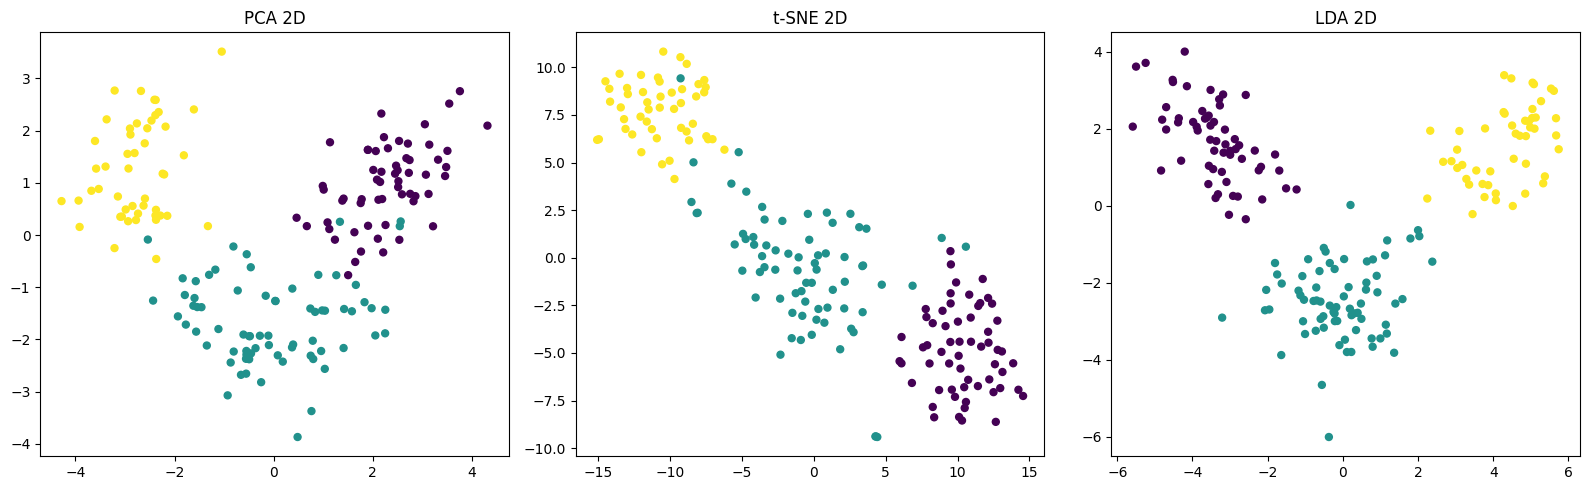

In [5]:
# ==========================================
# PRAKTIKUM BAB 11: REDUKSI DIMENSI (PCA, t-SNE, LDA)
# ==========================================

import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load dataset (menggunakan load_wine sebagai contoh data multikelas)
data = load_wine()
X, y = data.data, data.target

# Scaling data (wajib sebelum reduksi dimensi)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

print("=== PRAKTIKUM 1: KOMPRESI DIMENSI DENGAN PCA & EVALUASI MODEL ===")
# Praktikum 11.7: Evaluasi performa model dengan berbagai komponen PCA
for n_comp in [0.80, 0.90, 0.95, None]:
    pca_i = PCA(n_components=n_comp) if n_comp else PCA()
    X_train_p = pca_i.fit_transform(X_train)
    X_test_p = pca_i.transform(X_test)

    model = LogisticRegression(max_iter=2000)
    model.fit(X_train_p, y_train)

    acc = accuracy_score(y_test, model.predict(X_test_p))
    print(f"n_components={str(n_comp):5} | dimensi={X_train_p.shape[1]:2} | akurasi={acc:.3f}")


print("\n=== PRAKTIKUM 2: PERBANDINGAN VISUALISASI PCA, t-SNE, DAN LDA ===")
# Mereduksi dimensi langsung ke 2D untuk visualisasi
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

tsne_2d = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne_2d.fit_transform(X_scaled)

lda_2d = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda_2d.fit_transform(X_scaled, y) # LDA memerlukan label y (supervised)

# Plot perbandingan visualisasi 3 metode dalam satu figure berdampingan
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="viridis", s=25)
axes[0].set_title("PCA 2D")

axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap="viridis", s=25)
axes[1].set_title("t-SNE 2D")

axes[2].scatter(X_lda[:, 0], X_lda[:, 1], c=y, cmap="viridis", s=25)
axes[2].set_title("LDA 2D")

plt.tight_layout()
plt.show()